In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt

In [2]:
x = np.array([1,3,5,8,11,14,17,20]).reshape(-1,1)
y = np.array([10,15,22,35,50,65,72,75])


In [14]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

def poly_polynomial(degree, color, label):

    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(x)

    model = LinearRegression()
    model.fit(X_poly, y)

    x_smooth = np.linspace(0, 25, 200).reshape(-1, 1)
    x_smooth_poly = poly.transform(x_smooth)

    y_smooth = model.predict(x_smooth_poly)

    plt.plot(x_smooth, y_smooth,
             color=color,
             linewidth=3,
             label=label)

    coeffs = model.coef_
    intercept = model.intercept_

    print(f"\n{label} Equation")

    eq = f"y = {intercept:.2f}"

    for i, c in enumerate(coeffs, start=1):
        eq += f" + ({c:.3f})X^{i}"

    print(eq)

    return model, poly


Linear (Degree 1) Equation
y = 5.55 + (3.792)X^1

Quadratic (degree 2) Equation
y = 1.44 + (5.068)X^1 + (-0.062)X^2

cubic (degree 3) Equation
y = 9.18 + (0.555)X^1 + (0.479)X^2 + (-0.017)X^3


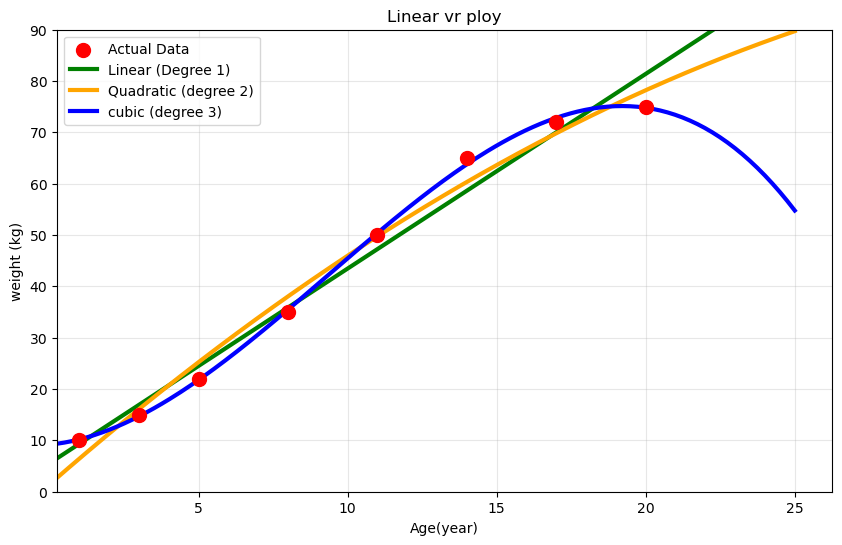

predicted weight at age 25 = 54.8kg


In [16]:
plt.figure(figsize=(10,6))
plt.scatter(x, y, color="red", s=100, label="Actual Data", zorder=5)
#linear (degree 1)
poly_polynomial(1, 'green', 'Linear (Degree 1)') 
#Quadratic (degree 2)
poly_polynomial(2,'orange','Quadratic (degree 2)')
#cubic (degree 3)
model_cubic, poly_cubic = poly_polynomial(3,'blue','cubic (degree 3)')
plt.xlabel('Age(year)')
plt.ylabel('weight (kg)')
plt.title("Linear vr ploy")
plt.legend()
plt.grid(True,alpha=0.3)
plt.ylim(0,90)
plt.xlim(0.25)
plt.show()

# predicted 
age_25 = poly_cubic.transform([[25]])
weight_25 = model_cubic.predict(age_25)
print(f"predicted weight at age 25 = {weight_25[0]:.1f}kg")



Linear (Degree 1) Equation
y = 5.55 + (3.792)X^1


(LinearRegression(), PolynomialFeatures(degree=1, include_bias=False))

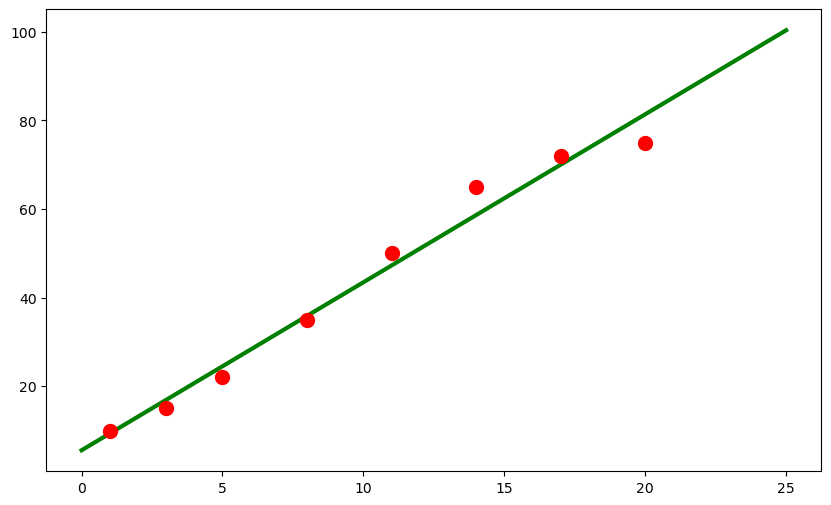